In [23]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np


In [24]:
# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [25]:
# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


In [26]:
# Dataset paths
base_dir = r"Skin Lesions Classification"
train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'test')


In [27]:
# Quick dataset check (run once)
for split_dir in [train_dir, test_dir]:
    classes = sorted([d for d in os.listdir(split_dir) if os.path.isdir(os.path.join(split_dir, d))])
    counts = {}
    for c in classes:
        cdir = os.path.join(split_dir, c)
        counts[c] = len([f for f in os.listdir(cdir) if os.path.isfile(os.path.join(cdir, f))])
    print(f"{os.path.basename(split_dir)} classes: {classes}")
    print(f"{os.path.basename(split_dir)} counts: {counts}")


train classes: ['benign', 'malignant']
train counts: {'benign': 1440, 'malignant': 1197}
test classes: ['benign', 'malignant']
test counts: {'benign': 361, 'malignant': 300}


In [28]:
# Image parameters
img_size = 224
batch_size = 32
num_classes = 2
num_epochs = 60
patience = 10
use_mixup = False
mixup_alpha = 0.05


In [29]:
# Data augmentation and normalization
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(img_size),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


In [30]:
# Stratified train/val split with separate transforms
base_dataset = datasets.ImageFolder(train_dir)
targets = np.array(base_dataset.targets)
indices = np.arange(len(targets))
train_idx, val_idx = train_test_split(
    indices, test_size=0.2, stratify=targets, random_state=42
)

train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
val_dataset = datasets.ImageFolder(train_dir, transform=val_test_transforms)
train_data = torch.utils.data.Subset(train_dataset, train_idx)
val_data = torch.utils.data.Subset(val_dataset, val_idx)
test_data = datasets.ImageFolder(test_dir, transform=val_test_transforms)

class_names = train_dataset.classes


In [31]:
# Dataloaders (single balancing: sampler only)
train_targets = targets[train_idx]
class_counts = np.bincount(train_targets)
class_weights = 1.0 / class_counts
sample_weights = class_weights[train_targets]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_data, batch_size=batch_size, sampler=sampler)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)


In [32]:
# Mixup helper
def mixup_data(x, y, alpha=0.2):
    if alpha <= 0:
        return x, y, y, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


In [33]:
# Define model (transfer learning)
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for param in model.parameters():
    param.requires_grad = False

in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, num_classes)
)
model = model.to(device)


In [34]:
# Loss, optimizer, scheduler
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.fc.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)


In [35]:
# Training loop with early stopping (monitor val loss)
best_val_loss = float('inf')
counter = 0
train_acc_hist, val_acc_hist = [], []
train_loss_hist, val_loss_hist = [], []

for epoch in range(num_epochs):
    model.train()
    train_loss, train_correct = 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        if use_mixup:
            mixed_x, y_a, y_b, lam = mixup_data(imgs, labels, mixup_alpha)
            outputs = model(mixed_x)
            loss = mixup_criterion(criterion, outputs, y_a, y_b, lam)
        else:
            outputs = model(imgs)
            loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels.data)

    train_loss /= len(train_loader.dataset)
    train_acc = train_correct.double() / len(train_loader.dataset)

    model.eval()
    val_loss, val_correct = 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct.double() / len(val_loader.dataset)

    train_acc_hist.append(train_acc.item())
    val_acc_hist.append(val_acc.item())
    train_loss_hist.append(train_loss)
    val_loss_hist.append(val_loss)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1}/{num_epochs}, "
          f"Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}, "
          f"Val Loss: {val_loss:.4f}")

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), 'skin_lesions_model_resnet18_v3.pth')
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping.")
            break

# Load best model
model.load_state_dict(torch.load('skin_lesions_model_resnet18_v3.pth'))


Epoch 1/60, Train Acc: 0.7027, Val Acc: 0.8239, Val Loss: 0.4166
Epoch 2/60, Train Acc: 0.7724, Val Acc: 0.8390, Val Loss: 0.3668
Epoch 3/60, Train Acc: 0.7975, Val Acc: 0.8466, Val Loss: 0.3669
Epoch 4/60, Train Acc: 0.7862, Val Acc: 0.8277, Val Loss: 0.3597
Epoch 5/60, Train Acc: 0.7876, Val Acc: 0.8466, Val Loss: 0.3367
Epoch 6/60, Train Acc: 0.7895, Val Acc: 0.8485, Val Loss: 0.3321
Epoch 7/60, Train Acc: 0.7899, Val Acc: 0.8466, Val Loss: 0.3792
Epoch 8/60, Train Acc: 0.8132, Val Acc: 0.8447, Val Loss: 0.3227
Epoch 9/60, Train Acc: 0.7952, Val Acc: 0.8371, Val Loss: 0.3952
Epoch 10/60, Train Acc: 0.8099, Val Acc: 0.8466, Val Loss: 0.3463
Epoch 11/60, Train Acc: 0.7994, Val Acc: 0.8390, Val Loss: 0.3227
Epoch 12/60, Train Acc: 0.8132, Val Acc: 0.8485, Val Loss: 0.3129
Epoch 13/60, Train Acc: 0.7994, Val Acc: 0.8598, Val Loss: 0.3167
Epoch 14/60, Train Acc: 0.8113, Val Acc: 0.8466, Val Loss: 0.3158
Epoch 15/60, Train Acc: 0.8160, Val Acc: 0.8636, Val Loss: 0.3278
Epoch 16/60, Train 

<All keys matched successfully>

In [36]:
# Fine-tuning (unfreeze layer2 + layer3 + layer4, use smaller LR)
for name, param in model.named_parameters():
    if name.startswith('layer2') or name.startswith('layer3') or name.startswith('layer4'):
        param.requires_grad = True

fine_tune_epochs = 20
optimizer = optim.AdamW([
    {'params': model.layer2.parameters(), 'lr': 5e-5},
    {'params': model.layer3.parameters(), 'lr': 5e-5},
    {'params': model.layer4.parameters(), 'lr': 1e-4},
    {'params': model.fc.parameters(), 'lr': 3e-4},
], weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

best_val_acc = 0.0
for epoch in range(fine_tune_epochs):
    model.train()
    train_loss, train_correct = 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        if use_mixup:
            mixed_x, y_a, y_b, lam = mixup_data(imgs, labels, mixup_alpha)
            outputs = model(mixed_x)
            loss = mixup_criterion(criterion, outputs, y_a, y_b, lam)
        else:
            outputs = model(imgs)
            loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels.data)

    train_loss /= len(train_loader.dataset)
    train_acc = train_correct.double() / len(train_loader.dataset)

    model.eval()
    val_loss, val_correct = 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct.double() / len(val_loader.dataset)
    scheduler.step(val_loss)

    print(f"Fine-tune Epoch {epoch+1}/{fine_tune_epochs}, "
          f"Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}, "
          f"Val Loss: {val_loss:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'skin_lesions_model_resnet18_v3.pth')

# Load best model from fine-tune
model.load_state_dict(torch.load('skin_lesions_model_resnet18_v3.pth'))


Fine-tune Epoch 1/20, Train Acc: 0.8122, Val Acc: 0.8598, Val Loss: 0.3029
Fine-tune Epoch 2/20, Train Acc: 0.8834, Val Acc: 0.8920, Val Loss: 0.2484
Fine-tune Epoch 3/20, Train Acc: 0.8687, Val Acc: 0.8807, Val Loss: 0.2471
Fine-tune Epoch 4/20, Train Acc: 0.8710, Val Acc: 0.8750, Val Loss: 0.2473
Fine-tune Epoch 5/20, Train Acc: 0.8777, Val Acc: 0.9015, Val Loss: 0.2364
Fine-tune Epoch 6/20, Train Acc: 0.8843, Val Acc: 0.9015, Val Loss: 0.2331
Fine-tune Epoch 7/20, Train Acc: 0.9052, Val Acc: 0.8769, Val Loss: 0.2825
Fine-tune Epoch 8/20, Train Acc: 0.9028, Val Acc: 0.8920, Val Loss: 0.2766
Fine-tune Epoch 9/20, Train Acc: 0.9037, Val Acc: 0.8902, Val Loss: 0.2625
Fine-tune Epoch 10/20, Train Acc: 0.9218, Val Acc: 0.9053, Val Loss: 0.2109
Fine-tune Epoch 11/20, Train Acc: 0.9322, Val Acc: 0.9034, Val Loss: 0.2320
Fine-tune Epoch 12/20, Train Acc: 0.9388, Val Acc: 0.9110, Val Loss: 0.2449
Fine-tune Epoch 13/20, Train Acc: 0.9365, Val Acc: 0.8864, Val Loss: 0.2850
Fine-tune Epoch 14/20

<All keys matched successfully>

In [37]:
# Test evaluation
model.eval()
test_correct = 0
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        test_correct += torch.sum(preds == labels.data)

test_acc = test_correct.double() / len(test_loader.dataset)
print(f"Test Accuracy: {test_acc:.4f}")


Test Accuracy: 0.8896


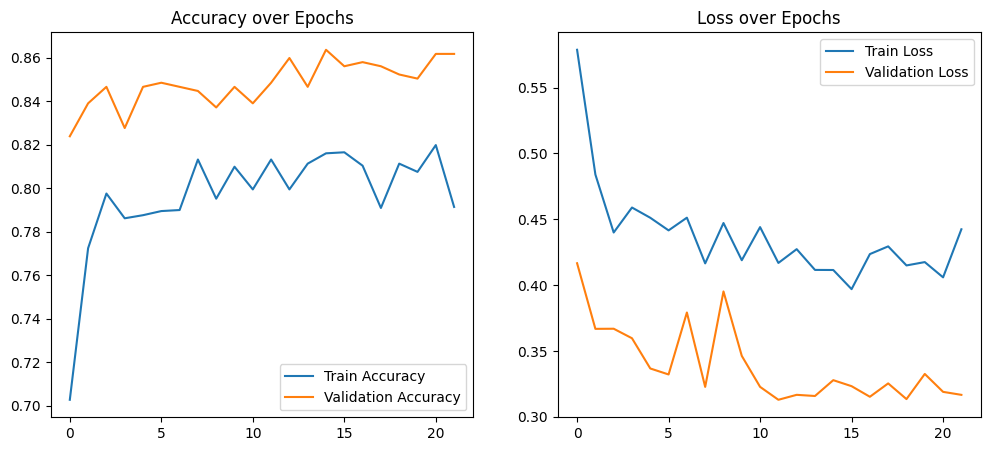

In [38]:
# Plot training history
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_acc_hist, label='Train Accuracy')
plt.plot(val_acc_hist, label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_loss_hist, label='Train Loss')
plt.plot(val_loss_hist, label='Validation Loss')
plt.title('Loss over Epochs')
plt.legend()
plt.show()


In [39]:
# Recreate model structure before loading weights
model = models.resnet18(weights=None)
in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, 2)
)
model.load_state_dict(torch.load('skin_lesions_model_resnet18_v3.pth'))
model.to(device)
model.eval()


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [40]:
from PIL import Image
from torchvision import transforms
import torch.nn.functional as F

# Transform used during testing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Class labels (must match training order)
class_names = class_names

def predict_image(image_path, model):
    image = Image.open(image_path).convert('RGB')
    img_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(img_tensor)
        probs = F.softmax(output, dim=1)
        confidence, pred_idx = torch.max(probs, 1)

    predicted_label = class_names[pred_idx.item()]
    return predicted_label, confidence.item()


In [41]:
image_path = r"Skin Lesions Classification\test\malignant\3.jpg"
label, confidence = predict_image(image_path, model)
print(f"Prediction: {label} ({confidence*100:.2f}% confidence)")


Prediction: malignant (100.00% confidence)


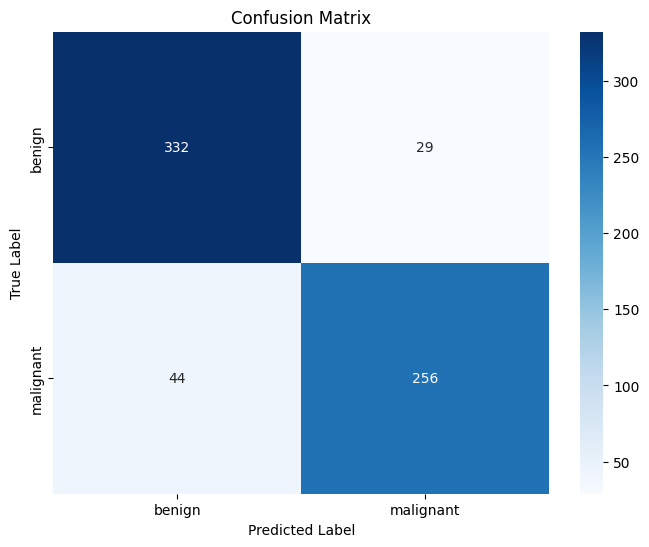

In [42]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Collect predictions and true labels
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


In [43]:
print("Classification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))


Classification Report:

              precision    recall  f1-score   support

      benign       0.88      0.92      0.90       361
   malignant       0.90      0.85      0.88       300

    accuracy                           0.89       661
   macro avg       0.89      0.89      0.89       661
weighted avg       0.89      0.89      0.89       661



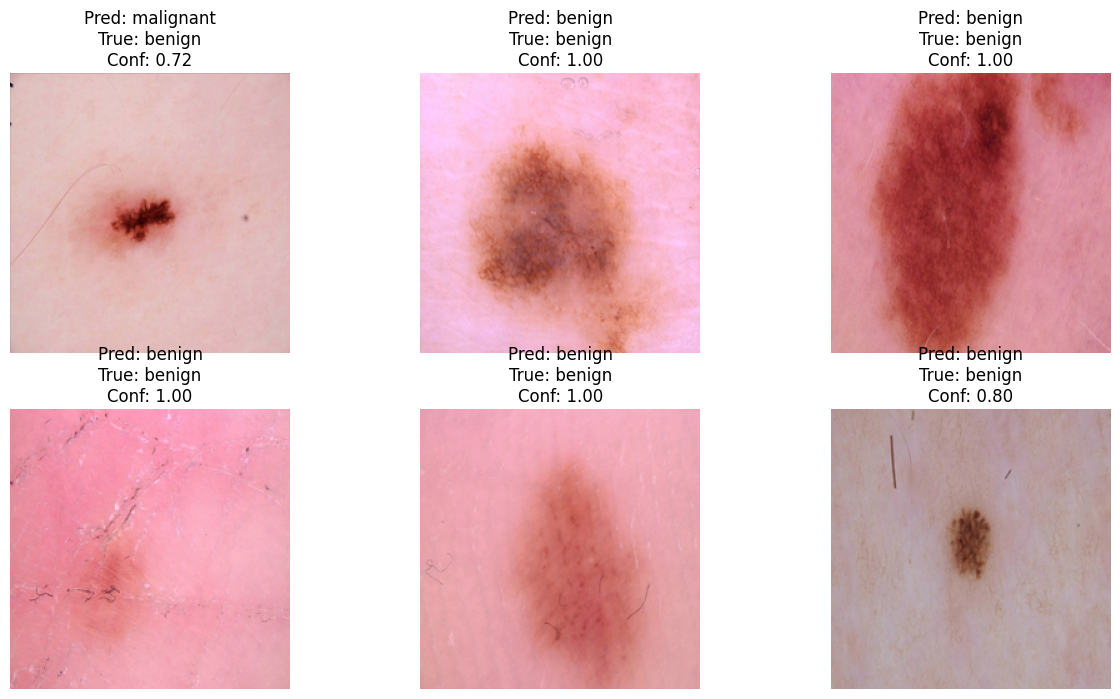

In [44]:
def visualize_predictions(model, data_loader, num_images=6):
    model.eval()
    images_shown = 0
    plt.figure(figsize=(15, 8))

    with torch.no_grad():
        for imgs, labels in data_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(probs, 1)

            for i in range(imgs.size(0)):
                if images_shown == num_images:
                    return
                image = imgs[i].cpu().permute(1, 2, 0).numpy()
                image = (image * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
                image = np.clip(image, 0, 1)
                plt.subplot(2, 3, images_shown+1)
                plt.imshow(image)
                plt.axis('off')
                plt.title(f"Pred: {class_names[preds[i]]}\nTrue: {class_names[labels[i]]}\nConf: {probs[i][preds[i]]:.2f}")
                images_shown += 1

visualize_predictions(model, test_loader)
